In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles in the current directory:")
print(list(Path.cwd().iterdir()))

Current working directory:
c:\Customer Churn Prediction

Files in the current directory:
[WindowsPath('c:/Customer Churn Prediction/.dist'), WindowsPath('c:/Customer Churn Prediction/.venv'), WindowsPath('c:/Customer Churn Prediction/01_data_exploration.ipynb'), WindowsPath('c:/Customer Churn Prediction/data')]


In [ ]:

import pandas as pd
from pathlib import Path

# Locate the dataset
DATA_PATH = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Load the data
df = pd.read_csv(DATA_PATH)

# Basic overview
print("CUSTOMER CHURN DATASET")
print("-" * 40)
print("Rows and columns:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nChurn distribution:")
print(df["Churn"].value_counts())


CUSTOMER CHURN DATASET
----------------------------------------
Rows and columns: (7043, 21)

First five rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fibe

In [ ]:
# Check column names and data types
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check unique customer IDs
print("Unique customers:", df["customerID"].nunique())

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


Duplicate rows: 0
Unique customers: 7043


In [ ]:
# Missing values
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing %": (missing / len(df) * 100).round(2)
})

display(missing_summary.sort_values("Missing Values", ascending=False))

# Inspect total charges
print("TotalCharges data type:", df["TotalCharges"].dtype)
display(df["TotalCharges"].head(10))

,Missing Values,Missing %
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


TotalCharges data type: str


0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str

In [ ]:
# Keep the original dataset unchanged
df_clean = df.copy()

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges after conversion:",
      df_clean["TotalCharges"].isna().sum())

# Remove duplicate customer records, if any
df_clean = df_clean.drop_duplicates(subset="customerID")

print("Cleaned dataset shape:", df_clean.shape)

Missing TotalCharges after conversion: 11
Cleaned dataset shape: (7043, 21)


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


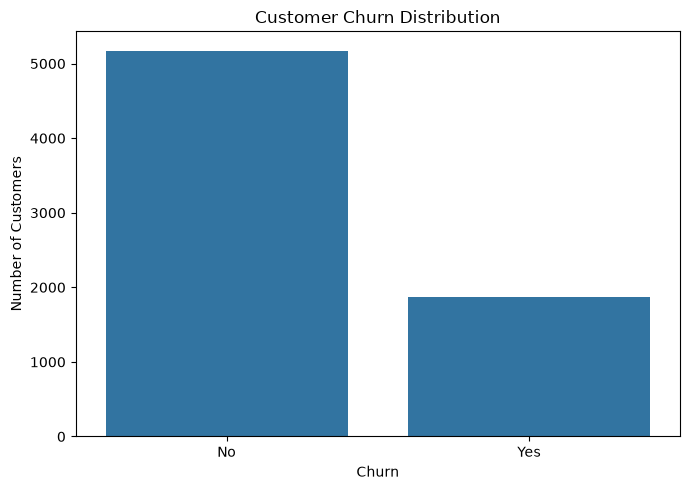

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

churn_counts = df_clean["Churn"].value_counts()

print(churn_counts)
print("\nChurn percentage:")
print((df_clean["Churn"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


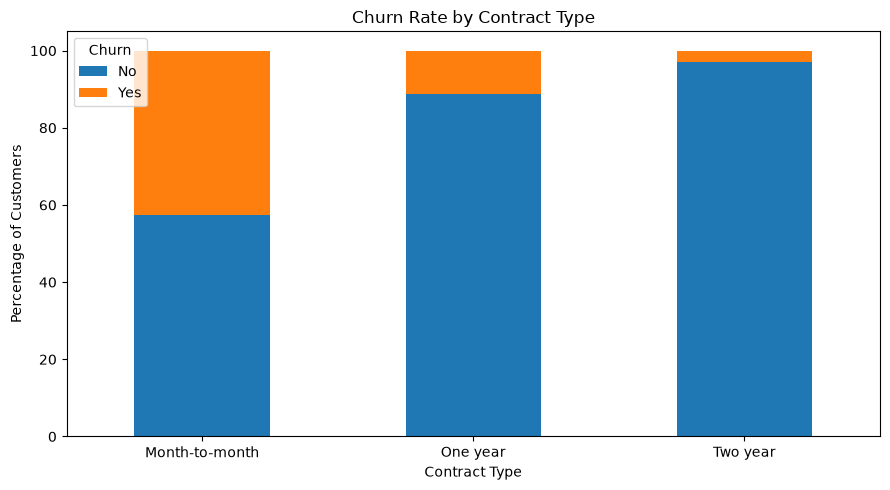

In [ ]:
contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

display(contract_churn.round(2))

contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

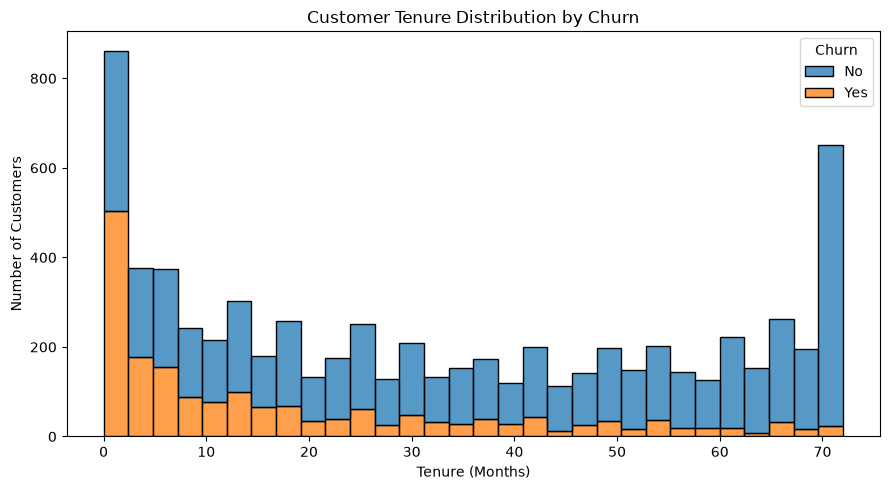

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [ ]:
tenure_summary = (
    df_clean.groupby("Churn")["tenure"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(tenure_summary)

,count,mean,median
Churn,,,
No,5174,37.57,38.0
Yes,1869,17.98,10.0


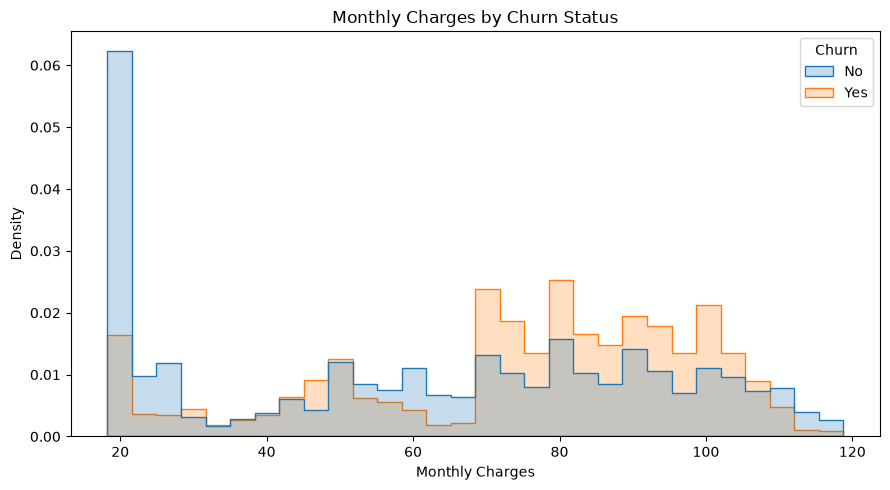

In [ ]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    multiple="layer",
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Monthly Charges")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


In [ ]:

for column in ["InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity"]:
    print(f"\nChurn rate by {column} (%)")

    churn_rate = (
        pd.crosstab(df_clean[column], df_clean["Churn"], normalize="index")["Yes"]
        .mul(100)
        .round(2)
        .sort_values(ascending=False)
    )

    display(churn_rate.to_frame("Churn Rate (%)"))



Churn rate by InternetService (%)


,Churn Rate (%)
InternetService,
Fiber optic,41.89
DSL,18.96
No,7.40



Churn rate by PaymentMethod (%)


,Churn Rate (%)
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24



Churn rate by TechSupport (%)


,Churn Rate (%)
TechSupport,
No,41.64
Yes,15.17
No internet service,7.40



Churn rate by OnlineSecurity (%)


,Churn Rate (%)
OnlineSecurity,
No,41.77
Yes,14.61
No internet service,7.40


In [ ]:

# Check the target labels
print(df_clean["Churn"].value_counts(dropna=False))

# Convert target to 0 and 1
df_model = df_clean.copy()
df_model["Churn"] = df_model["Churn"].map({"No": 0, "Yes": 1})

# Remove customer ID because it is an identifier, not a useful predictive feature
X = df_model.drop(columns=["Churn", "customerID"])
y = df_model["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Churn rate:", round(y.mean() * 100, 2), "%")


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Features shape: (7043, 19)
Target shape: (7043,)
Churn rate: 26.54 %


In [ ]:

from sklearn.model_selection import train_test_split

# Separate numerical and categorical features
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

print("Missing values in target:", y.isna().sum())
print("Missing values in features:", X.isna().sum().sum())


Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Missing values in target: 0
Missing values in features: 11


C:\Users\raedh\AppData\Local\Temp\ipykernel_7248\843327935.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

print("Pipeline created successfully!")


Pipeline created successfully!


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

print("Training completed!")
print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))


Training completed!
Training customers: 5634
Testing customers: 1409


Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1-score: 0.604
ROC-AUC: 0.8419

Detailed classification report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



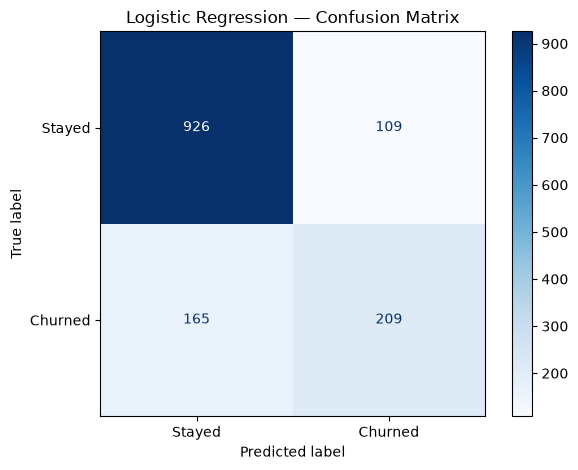

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nDetailed classification report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

def evaluate_model(name, fitted_model, X_test, y_test):
    predictions = fitted_model.predict(X_test)
    probabilities = fitted_model.predict_proba(X_test)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

results = pd.DataFrame([
    evaluate_model("Logistic Regression", model, X_test, y_test),
    evaluate_model("Random Forest", rf_model, X_test, y_test)
])

display(results.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.806,0.657,0.559,0.604,0.842
1,Random Forest,0.760,0.536,0.714,0.612,0.835


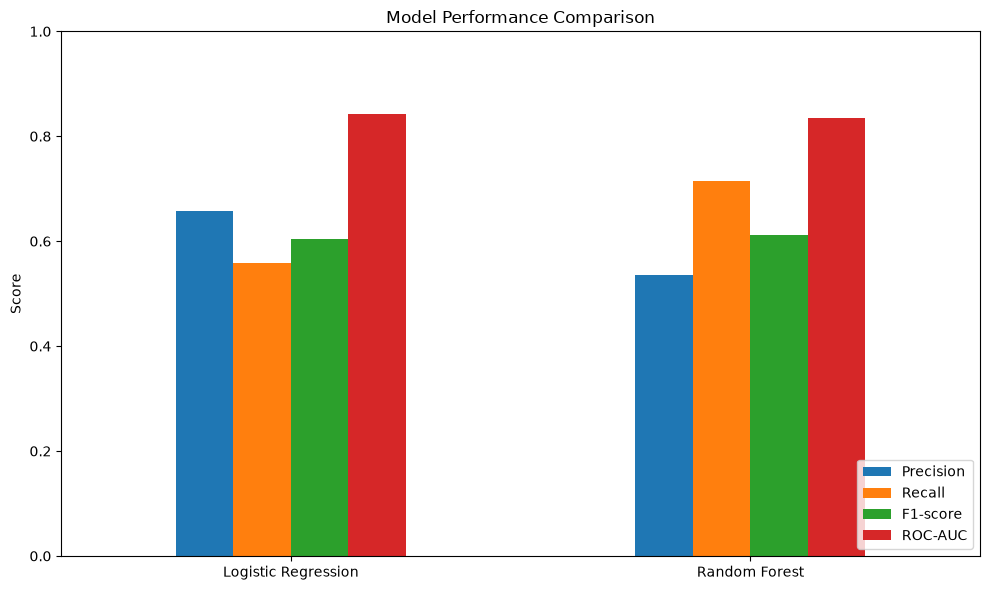

In [ ]:

results.set_index("Model")[["Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


,Feature,Importance
1,numeric__tenure,0.1295
3,numeric__TotalCharges,0.1230
2,numeric__MonthlyCharges,0.0986
36,categorical__Contract_Month-to-month,0.0961
38,categorical__Contract_Two year,0.0483
18,categorical__OnlineSecurity_No,0.0463
27,categorical__TechSupport_No,0.0373
16,categorical__InternetService_Fiber optic,0.0366
43,categorical__PaymentMethod_Electronic check,0.0330
37,categorical__Contract_One year,0.0178


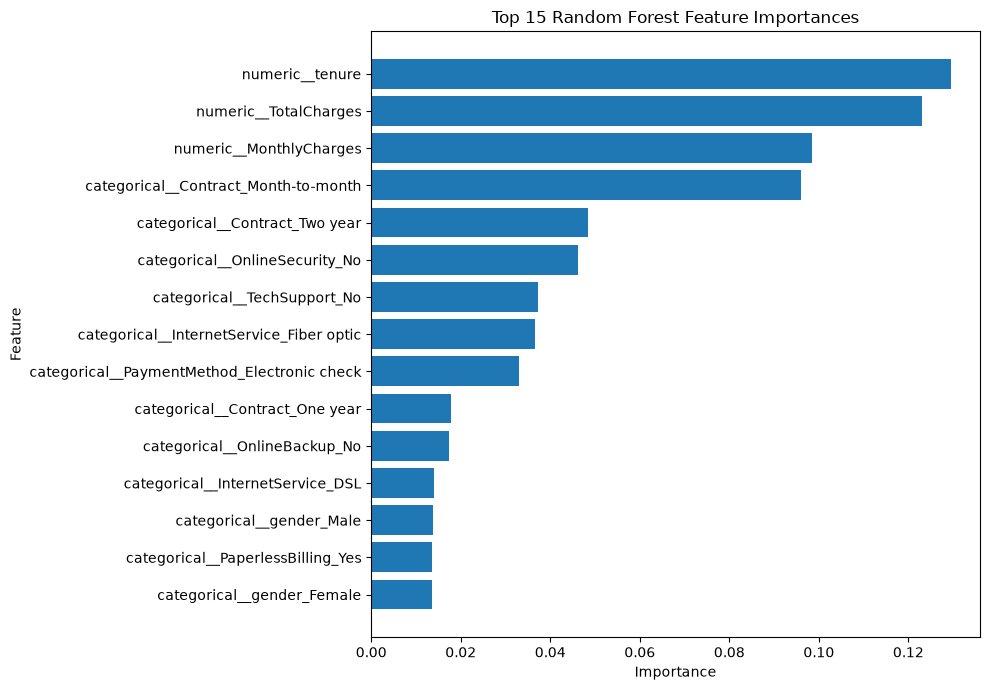

In [ ]:

# Get the transformed feature names
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

# Get Random Forest feature importance
importances = rf_model.named_steps["classifier"].feature_importances_

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })
    .sort_values("Importance", ascending=False)
)

display(feature_importance.head(15).round(4))

# Plot the top 15 features
top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [ ]:
# Create a table with actual and predicted churn
predictions_df = X_test.copy()

predictions_df["Actual_Churn"] = y_test
predictions_df["Predicted_Churn"] = rf_model.predict(X_test)
predictions_df["Churn_Probability"] = (
    rf_model.predict_proba(X_test)[:, 1]
)

display(
    predictions_df[
        [
            "tenure",
            "Contract",
            "MonthlyCharges",
            "Actual_Churn",
            "Predicted_Churn",
            "Churn_Probability"
        ]
    ].head(10).round(3)
)

,tenure,Contract,MonthlyCharges,Actual_Churn,Predicted_Churn,Churn_Probability
437,72,Two year,114.05,0,0,0.010
2280,8,Month-to-month,100.15,0,1,0.828
2235,41,One year,78.35,0,0,0.098
4460,18,Month-to-month,78.20,0,0,0.431
3761,72,Two year,82.65,0,0,0.035
5748,21,Month-to-month,99.85,0,1,0.720
3568,21,Month-to-month,99.15,0,1,0.546
2976,19,Month-to-month,24.10,0,0,0.232
5928,61,Two year,19.75,0,0,0.005
1639,17,Month-to-month,45.05,1,1,0.569


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred_rf = rf_model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Stayed", "Churned"]
))

Confusion Matrix:
[[804 231]
 [107 267]]

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.88      0.78      0.83      1035
     Churned       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_rf)

print(cm)

[[804 231]
 [107 267]]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

def evaluate_model(name, fitted_model):
    predictions = fitted_model.predict(X_test)
    probabilities = fitted_model.predict_proba(X_test)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

results = pd.DataFrame([
    evaluate_model("Logistic Regression", model),
    evaluate_model("Random Forest", rf_model)
])

display(results.round(3))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.806,0.657,0.559,0.604,0.842
1,Random Forest,0.760,0.536,0.714,0.612,0.835


In [ ]:

from sklearn.metrics import confusion_matrix

y_pred_rf = rf_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_rf)
print(cm)


[[804 231]
 [107 267]]


In [ ]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Get churn probabilities once
churn_probabilities = rf_model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.3, 0.4, 0.5]:
    predictions = (churn_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))


,Threshold,Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives
0,0.3,0.686,0.453,0.885,0.600,399,43,331
1,0.4,0.737,0.503,0.816,0.622,301,69,305
2,0.5,0.760,0.536,0.714,0.612,231,107,267


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone

# Split the existing training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Create a fresh copy of the Random Forest pipeline
rf_candidate = clone(rf_model)

# Train only on the fitting subset
rf_candidate.fit(X_fit, y_fit)

print("Model training rows:", len(X_fit))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))


Model training rows: 4507
Validation rows: 1127
Test rows: 1409


In [ ]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Predict churn probabilities on validation data
val_probabilities = rf_candidate.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in [0.3, 0.4, 0.5]:
    val_predictions = (val_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, val_predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, val_predictions),
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_predictions, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

validation_results = pd.DataFrame(threshold_results)

display(validation_results.round(3))


,Threshold,Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives
0,0.3,0.681,0.449,0.876,0.593,322,37,262
1,0.4,0.740,0.506,0.799,0.620,233,60,239
2,0.5,0.770,0.551,0.722,0.625,176,83,216


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

# Predict probabilities on the untouched test set
test_probabilities = rf_candidate.predict_proba(X_test)[:, 1]

# Apply the selected threshold
selected_threshold = 0.4
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

print(f"Selected threshold: {selected_threshold}")
print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_predictions, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Stayed", "Churned"],
    zero_division=0
))


Selected threshold: 0.4

Confusion matrix:
[[731 304]
 [ 70 304]]

Classification report:
              precision    recall  f1-score   support

      Stayed       0.91      0.71      0.80      1035
     Churned       0.50      0.81      0.62       374

    accuracy                           0.73      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.73      0.75      1409



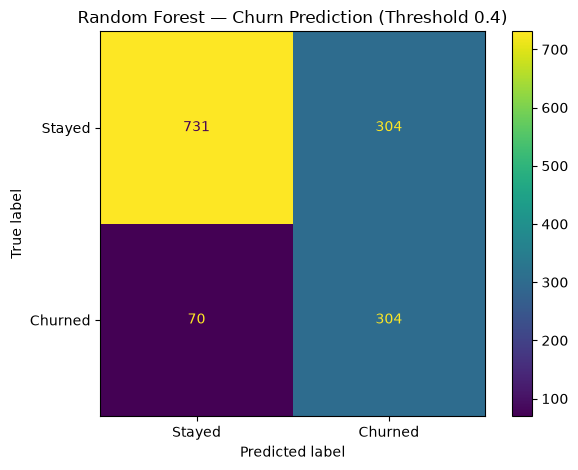

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

display_plot.plot(values_format="d")
plt.title("Random Forest — Churn Prediction (Threshold 0.4)")
plt.tight_layout()
plt.show()


In [ ]:
print("y_test exists:", "y_test" in globals())
print("test_predictions exists:", "test_predictions" in globals())
print("rf_candidate exists:", "rf_candidate" in globals())

y_test exists: True
test_predictions exists: True
rf_candidate exists: True


In [ ]:

# STEP 1: Identify customers at risk of churning

import pandas as pd
import numpy as np

# Build a customer-level prediction table
risk_df = X_test.copy()

risk_df["Actual_Churn"] = y_test
risk_df["Churn_Probability"] = test_probabilities
risk_df["Predicted_Churn"] = test_predictions

# Assign a business-friendly risk category
risk_df["Risk_Level"] = pd.cut(
    risk_df["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"]
)

# Estimate monthly charges associated with each customer
risk_df["Monthly_Revenue_At_Risk"] = np.where(
    risk_df["Predicted_Churn"] == 1,
    risk_df["MonthlyCharges"],
    0
)

# Sort customers by churn probability
risk_df = risk_df.sort_values(
    "Churn_Probability",
    ascending=False
)

# Display the 20 highest-risk customers
columns_to_show = [
    "tenure",
    "Contract",
    "MonthlyCharges",
    "Churn_Probability",
    "Risk_Level",
    "Predicted_Churn",
    "Actual_Churn"
]

display(risk_df[columns_to_show].head(20).round(3))

# Summarize the predicted customer risk
print("\nCUSTOMER RISK SUMMARY")
print("=" * 35)

print("\nCustomers by risk level:")
display(
    risk_df["Risk_Level"]
    .value_counts()
    .reindex(["High", "Medium", "Low"])
    .rename_axis("Risk Level")
    .to_frame("Number of Customers")
)

print("\nEstimated monthly charges associated with predicted churn:")
print(
    "€" + f"{risk_df['Monthly_Revenue_At_Risk'].sum():,.2f}"
)


,tenure,Contract,MonthlyCharges,Churn_Probability,Risk_Level,Predicted_Churn,Actual_Churn
2194,1,Month-to-month,79.50,0.993,High,1,1
6623,1,Month-to-month,76.45,0.986,High,1,1
4585,1,Month-to-month,85.05,0.981,High,1,1
1144,1,Month-to-month,35.55,0.980,High,1,1
1731,1,Month-to-month,69.60,0.977,High,1,1
2729,2,Month-to-month,85.70,0.977,High,1,1
3346,2,Month-to-month,84.05,0.975,High,1,0
809,1,Month-to-month,69.55,0.972,High,1,1
2464,1,Month-to-month,77.15,0.971,High,1,1
2927,1,Month-to-month,69.90,0.970,High,1,0



CUSTOMER RISK SUMMARY

Customers by risk level:


,Number of Customers
Risk Level,
High,389
Medium,347
Low,673



Estimated monthly charges associated with predicted churn:
€44,934.95


REVENUE AT RISK
Test customers: 1,409
Customers flagged at risk: 608
Percentage flagged: 43.15%
Associated monthly charges: €44,934.95
Annualized equivalent: €539,219.40


,Customer Group,Customers
0,Actual Churn,374
1,Predicted Churn,608


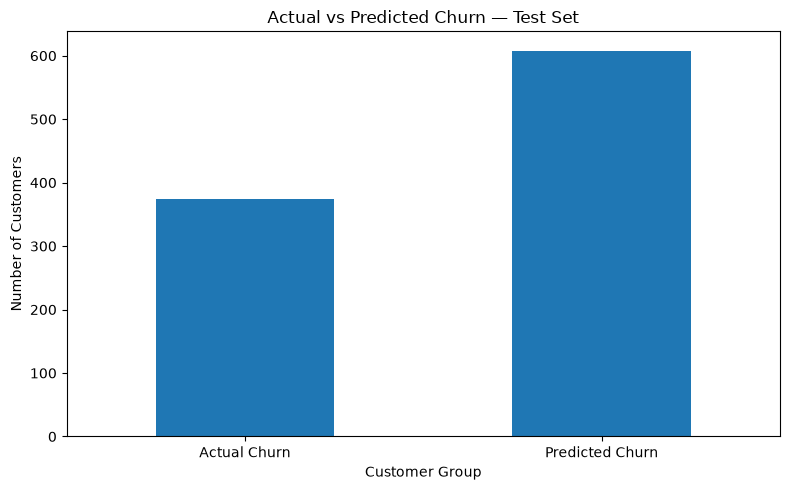


REVENUE EXPOSURE BY CONTRACT


,Customers,Monthly_Charges,Average_Monthly_Charge
Contract,,,
Month-to-month,573,41716.35,72.80
One year,34,3110.05,91.47
Two year,1,108.55,108.55


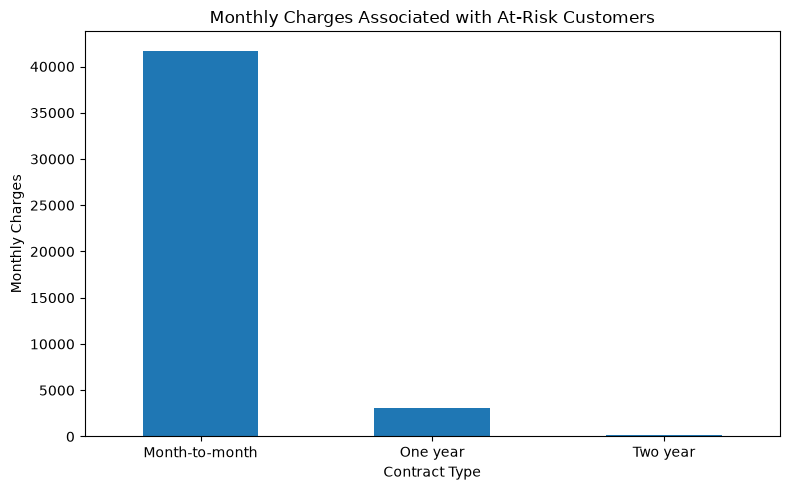

In [ ]:

# STEP 2: Revenue at Risk Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create a fresh analysis table from test-set predictions
revenue_df = X_test.copy()

revenue_df["Actual_Churn"] = y_test
revenue_df["Churn_Probability"] = test_probabilities
revenue_df["Predicted_Churn"] = test_predictions

# Identify customers flagged as likely to churn
revenue_df["Predicted_Risk"] = (
    revenue_df["Churn_Probability"] >= selected_threshold
)

# 1. Overall revenue exposure
total_customers = len(revenue_df)
predicted_churners = int(revenue_df["Predicted_Risk"].sum())

monthly_revenue_at_risk = revenue_df.loc[
    revenue_df["Predicted_Risk"], "MonthlyCharges"
].sum()

annualized_revenue_at_risk = monthly_revenue_at_risk * 12

print("REVENUE AT RISK")
print("=" * 40)
print(f"Test customers: {total_customers:,}")
print(f"Customers flagged at risk: {predicted_churners:,}")
print(
    f"Percentage flagged: "
    f"{predicted_churners / total_customers * 100:.2f}%"
)
print(f"Associated monthly charges: €{monthly_revenue_at_risk:,.2f}")
print(
    f"Annualized equivalent: €{annualized_revenue_at_risk:,.2f}"
)

# 2. Compare actual churn with predicted churn
comparison = pd.DataFrame({
    "Customer Group": ["Actual Churn", "Predicted Churn"],
    "Customers": [
        int(revenue_df["Actual_Churn"].sum()),
        predicted_churners
    ]
})

display(comparison)

comparison.plot(
    x="Customer Group",
    y="Customers",
    kind="bar",
    legend=False,
    figsize=(8, 5)
)
plt.title("Actual vs Predicted Churn — Test Set")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Monthly charges by predicted risk
risk_revenue = (
    revenue_df[revenue_df["Predicted_Risk"]]
    .groupby("Contract", observed=True)
    .agg(
        Customers=("MonthlyCharges", "size"),
        Monthly_Charges=("MonthlyCharges", "sum"),
        Average_Monthly_Charge=("MonthlyCharges", "mean")
    )
    .sort_values("Monthly_Charges", ascending=False)
    .round(2)
)

print("\nREVENUE EXPOSURE BY CONTRACT")
display(risk_revenue)

risk_revenue["Monthly_Charges"].plot(
    kind="bar",
    figsize=(8, 5)
)
plt.title("Monthly Charges Associated with At-Risk Customers")
plt.xlabel("Contract Type")
plt.ylabel("Monthly Charges")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


TOP 15 FEATURES ASSOCIATED WITH CHURN PREDICTION


,Feature,Importance
1,numeric__tenure,0.1269
3,numeric__TotalCharges,0.1196
36,categorical__Contract_Month-to-month,0.1028
2,numeric__MonthlyCharges,0.0963
38,categorical__Contract_Two year,0.0496
18,categorical__OnlineSecurity_No,0.0469
27,categorical__TechSupport_No,0.0398
16,categorical__InternetService_Fiber optic,0.0380
43,categorical__PaymentMethod_Electronic check,0.0293
21,categorical__OnlineBackup_No,0.0181


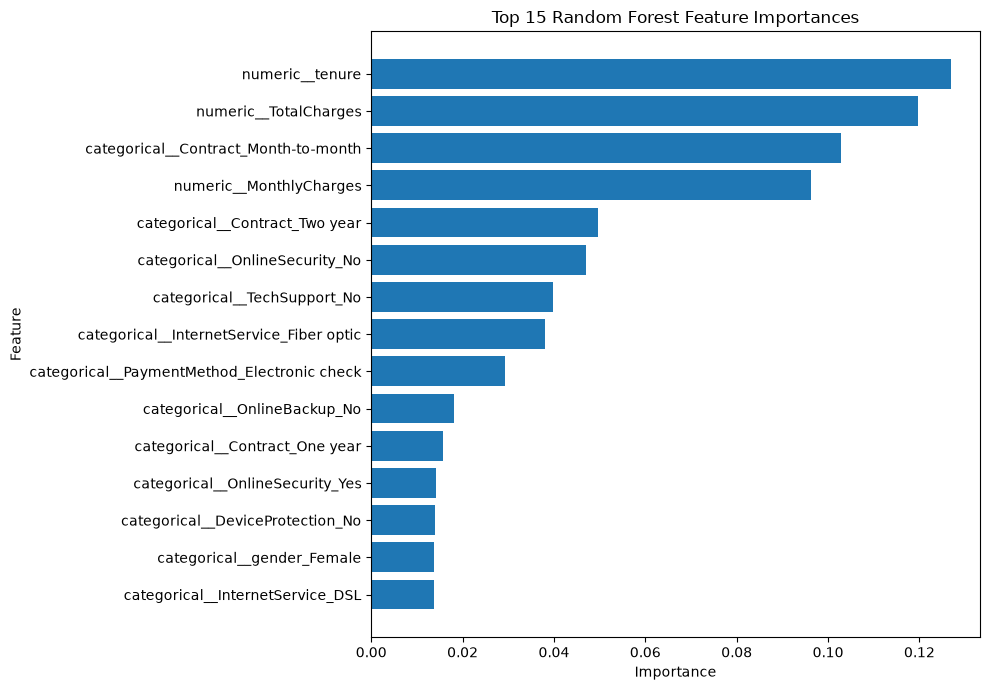

In [ ]:

# STEP 3: Feature Importance Analysis

feature_names = (
    rf_candidate.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    rf_candidate.named_steps["classifier"]
    .feature_importances_
)

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })
    .sort_values("Importance", ascending=False)
)

print("TOP 15 FEATURES ASSOCIATED WITH CHURN PREDICTION")
display(feature_importance.head(15).round(4))

top_features = (
    feature_importance.head(15)
    .sort_values("Importance", ascending=True)
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 4: Customer Retention Recommendations

import pandas as pd
import numpy as np

# Create a customer-level retention table from the test set
retention_df = X_test.copy()

retention_df["Churn_Probability"] = test_probabilities
retention_df["Predicted_Churn"] = test_predictions

# Assign risk categories
retention_df["Risk_Level"] = pd.cut(
    retention_df["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"]
)

# Define retention recommendations
def recommend_action(row):
    actions = []

    if row["Risk_Level"] == "High":
        actions.append("Contact customer urgently")
    elif row["Risk_Level"] == "Medium":
        actions.append("Offer proactive retention support")
    else:
        actions.append("Monitor customer satisfaction")

    if row["Contract"] == "Month-to-month":
        actions.append("Offer a suitable longer-term plan")

    if row["tenure"] <= 12:
        actions.append("Provide onboarding and early-life support")

    if row.get("TechSupport") == "No":
        actions.append("Explain available technical support")

    if row.get("OnlineSecurity") == "No":
        actions.append("Review online security options")

    return "; ".join(actions)

retention_df["Recommended_Action"] = retention_df.apply(
    recommend_action, axis=1
)

# Rank highest-risk customers first
retention_df = retention_df.sort_values(
    "Churn_Probability", ascending=False
)

# Show the top 20 customers
display(
    retention_df[
        [
            "tenure",
            "Contract",
            "MonthlyCharges",
            "Churn_Probability",
            "Risk_Level",
            "Recommended_Action"
        ]
    ].head(20).round(3)
)

print("\nRetention priority summary:")
display(
    retention_df.groupby("Risk_Level", observed=False)
    .agg(
        Customers=("Churn_Probability", "size"),
        Average_Churn_Probability=("Churn_Probability", "mean"),
        Monthly_Charges=("MonthlyCharges", "sum")
    )
    .round(2)
)


,tenure,Contract,MonthlyCharges,Churn_Probability,Risk_Level,Recommended_Action
2194,1,Month-to-month,79.50,0.993,High,Contact customer urgently; Offer a suitable lo...
6623,1,Month-to-month,76.45,0.986,High,Contact customer urgently; Offer a suitable lo...
4585,1,Month-to-month,85.05,0.981,High,Contact customer urgently; Offer a suitable lo...
1144,1,Month-to-month,35.55,0.980,High,Contact customer urgently; Offer a suitable lo...
1731,1,Month-to-month,69.60,0.977,High,Contact customer urgently; Offer a suitable lo...
2729,2,Month-to-month,85.70,0.977,High,Contact customer urgently; Offer a suitable lo...
3346,2,Month-to-month,84.05,0.975,High,Contact customer urgently; Offer a suitable lo...
809,1,Month-to-month,69.55,0.972,High,Contact customer urgently; Offer a suitable lo...
2464,1,Month-to-month,77.15,0.971,High,Contact customer urgently; Offer a suitable lo...
2927,1,Month-to-month,69.90,0.970,High,Contact customer urgently; Offer a suitable lo...



Retention priority summary:


,Customers,Average_Churn_Probability,Monthly_Charges
Risk_Level,,,
Low,673,0.11,36358.45
Medium,347,0.44,24442.20
High,389,0.77,29500.55


In [ ]:

# Export retention analysis results

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Export the full test-set retention list
retention_df.to_csv(
    output_dir / "customer_retention_priorities.csv",
    index=True,
    index_label="Customer_Index"
)

# Export a summary by risk level
retention_summary = (
    retention_df.groupby("Risk_Level", observed=False)
    .agg(
        Customers=("Churn_Probability", "size"),
        Average_Churn_Probability=("Churn_Probability", "mean"),
        Monthly_Charges=("MonthlyCharges", "sum")
    )
    .round(2)
)

retention_summary.to_csv(
    output_dir / "retention_risk_summary.csv"
)

print("Files exported successfully:")
print(output_dir / "customer_retention_priorities.csv")
print(output_dir / "retention_risk_summary.csv")


Files exported successfully:
outputs\customer_retention_priorities.csv
outputs\retention_risk_summary.csv


In [ ]:

# STEP 6: Prepare the full dataset for Power BI

import pandas as pd
import numpy as np
from pathlib import Path

# Use the cleaned original dataset and the trained model
dashboard_df = df_clean.copy()

# Keep customer IDs for dashboard filtering and customer-level analysis
customer_ids = dashboard_df["customerID"].copy()

# Prepare features in the same format used during training
X_all = dashboard_df.drop(columns=["customerID", "Churn"])

# Score all customers
all_probabilities = rf_candidate.predict_proba(X_all)[:, 1]

dashboard_df["Churn_Probability"] = all_probabilities
dashboard_df["Predicted_Churn"] = (
    all_probabilities >= selected_threshold
).astype(int)

# Business-friendly labels
dashboard_df["Risk_Level"] = pd.cut(
    dashboard_df["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"]
)

# Estimated monthly charges associated with flagged customers
dashboard_df["Monthly_Charges_At_Risk"] = np.where(
    dashboard_df["Predicted_Churn"] == 1,
    dashboard_df["MonthlyCharges"],
    0
)

# Suggested retention action
def retention_action(row):
    actions = []

    if row["Risk_Level"] == "High":
        actions.append("Prioritize retention contact")
    elif row["Risk_Level"] == "Medium":
        actions.append("Proactive satisfaction check")
    else:
        actions.append("Routine customer monitoring")

    if row["Contract"] == "Month-to-month":
        actions.append("Review longer-term plan options")

    if row["tenure"] <= 12:
        actions.append("Review onboarding experience")

    return "; ".join(actions)

dashboard_df["Recommended_Action"] = dashboard_df.apply(
    retention_action, axis=1
)

# Include actual churn for historical analysis
# This is known in the historical dataset, not a future outcome.
dashboard_df["Actual_Churn_Flag"] = (
    dashboard_df["Churn"].map({"No": 0, "Yes": 1})
)

# Keep customer IDs in the exported dataset
dashboard_df["customerID"] = customer_ids

# Export dashboard dataset
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

dashboard_path = output_dir / "customer_churn_dashboard.csv"
dashboard_df.to_csv(dashboard_path, index=False)

# Export an aggregate summary
summary = (
    dashboard_df.groupby("Risk_Level", observed=False)
    .agg(
        Customers=("customerID", "count"),
        Average_Churn_Probability=("Churn_Probability", "mean"),
        Monthly_Charges_At_Risk=("Monthly_Charges_At_Risk", "sum")
    )
    .round(3)
)

summary.to_csv(output_dir / "customer_churn_summary.csv")

print("Dashboard files created successfully!")
print("Main dataset:", dashboard_path)
print("Summary:", output_dir / "customer_churn_summary.csv")

print("\nTotal customers:", len(dashboard_df))
print("Predicted churners:", int(dashboard_df["Predicted_Churn"].sum()))
print("\nRisk summary:")
display(summary)


Dashboard files created successfully!
Main dataset: outputs\customer_churn_dashboard.csv
Summary: outputs\customer_churn_summary.csv

Total customers: 7043
Predicted churners: 2897

Risk summary:


,Customers,Average_Churn_Probability,Monthly_Charges_At_Risk
Risk_Level,,,
Low,3553,0.106,0.0
Medium,1503,0.440,62986.4
High,1987,0.794,151864.5


In [1]:

import pandas as pd
from pathlib import Path

file_path = Path("outputs/customer_churn_dashboard.csv")
dashboard = pd.read_csv(file_path)

print("Rows:", len(dashboard))
print("Unique customers:", dashboard["customerID"].nunique())
print("\nMissing values:")
print(dashboard[[
    "Churn_Probability",
    "Predicted_Churn",
    "Risk_Level",
    "Actual_Churn_Flag"
]].isna().sum())

print("\nRisk distribution:")
print(dashboard["Risk_Level"].value_counts(dropna=False))

print("\nActual churn rate:")
print(dashboard["Actual_Churn_Flag"].mean())

print("\nPredicted at-risk customers:")
print(dashboard["Predicted_Churn"].sum())


Rows: 7043
Unique customers: 7043

Missing values:
Churn_Probability    0
Predicted_Churn      0
Risk_Level           0
Actual_Churn_Flag    0
dtype: int64

Risk distribution:
Risk_Level
Low       3553
High      1987
Medium    1503
Name: count, dtype: int64

Actual churn rate:
0.2653698707936959

Predicted at-risk customers:
2897
